# Data Exploration

In [ ]:
import pandas as pd
import numpy as np
import re

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from rdkit import Chem
from rdkit.Chem import AllChem, Descriptors, Draw, rdMolDescriptors

## Import Excel and Clean Data

In [64]:
df = pd.read_pickle(r'Data and variables\dippr_db_extract.pkl')
df['Family'] = df['Family'].str.upper()
df.head()

,ChemID,Name,Formula,SMILES,Structure,Family,Sub_Family,Std_State,T,Surface_tension,...,TPT,Note,Data_Type,Source_Type,Source_Detail,Error,Error_Source,Acceptance,source_type_simplified,error_numeric
0,1942,BORON TRIFLUORIDE,BF3,FB(F)F,BF3,INORGANIC GASES,NaN,V,157.149994,0.02070,...,144.79,NaN,Smoothed,Unevaluated,Undocumented,< 5%,Staff,A,correlated,0.05
1,1942,BORON TRIFLUORIDE,BF3,FB(F)F,BF3,INORGANIC GASES,NaN,V,163.149994,0.01940,...,144.79,NaN,Smoothed,Unevaluated,Undocumented,< 5%,Staff,A,correlated,0.05
2,1942,BORON TRIFLUORIDE,BF3,FB(F)F,BF3,INORGANIC GASES,NaN,V,173.149994,0.01720,...,144.79,NaN,Smoothed,Unevaluated,Undocumented,< 5%,Staff,A,correlated,0.05
3,1942,BORON TRIFLUORIDE,BF3,FB(F)F,BF3,INORGANIC GASES,NaN,V,180.550003,0.01560,...,144.79,NaN,Smoothed,Unevaluated,Undocumented,< 5%,Staff,A,correlated,0.05
4,1942,BORON TRIFLUORIDE,BF3,FB(F)F,BF3,INORGANIC GASES,NaN,V,168.199997,0.01828,...,144.79,NaN,Predicted,Unevaluated,Undocumented,< 5%,Staff,N,correlated,0.05


### ST units Change

Surface Tension is usually represented as mN/m, so we need to transform that column  to better represent the values.

In [65]:
df["Surface_tension"] = df["Surface_tension"]*1000
df.head()

,ChemID,Name,Formula,SMILES,Structure,Family,Sub_Family,Std_State,T,Surface_tension,...,TPT,Note,Data_Type,Source_Type,Source_Detail,Error,Error_Source,Acceptance,source_type_simplified,error_numeric
0,1942,BORON TRIFLUORIDE,BF3,FB(F)F,BF3,INORGANIC GASES,NaN,V,157.149994,20.70,...,144.79,NaN,Smoothed,Unevaluated,Undocumented,< 5%,Staff,A,correlated,0.05
1,1942,BORON TRIFLUORIDE,BF3,FB(F)F,BF3,INORGANIC GASES,NaN,V,163.149994,19.40,...,144.79,NaN,Smoothed,Unevaluated,Undocumented,< 5%,Staff,A,correlated,0.05
2,1942,BORON TRIFLUORIDE,BF3,FB(F)F,BF3,INORGANIC GASES,NaN,V,173.149994,17.20,...,144.79,NaN,Smoothed,Unevaluated,Undocumented,< 5%,Staff,A,correlated,0.05
3,1942,BORON TRIFLUORIDE,BF3,FB(F)F,BF3,INORGANIC GASES,NaN,V,180.550003,15.60,...,144.79,NaN,Smoothed,Unevaluated,Undocumented,< 5%,Staff,A,correlated,0.05
4,1942,BORON TRIFLUORIDE,BF3,FB(F)F,BF3,INORGANIC GASES,NaN,V,168.199997,18.28,...,144.79,NaN,Predicted,Unevaluated,Undocumented,< 5%,Staff,N,correlated,0.05


### Error and Acceptance filtering

What the Acceptance codes mean:  
- A: Accepted. Data accepted (recommended) by project staff.  
- N: Not used (but acceptable). Data acceptable but of equal or less accuracy than the accepted value… within twice the uncertainty… or not used due to inconsistent trends.
- U: Unevaluated. Data not yet evaluated by project staff.
- R: Rejected. Data rejected… because they deviate… by more than twice the uncertainty… or are considered unreliable.

In [66]:
df["Acceptance"].value_counts()

Acceptance
A    38122
N     8022
U     4416
R     1665
Name: count, dtype: int64

In [67]:
# Take only the accepted ones  (more reliable)
df = df[df["Acceptance"] == "A"]

# Take only the ones with uncertainties <= 25% 
df = df[df["error_numeric"] <= 0.25]

df = df[df["Std_State"] == 'L']

### Elements filtering
Let's filter the SMILES, so we can concentrate in molecules that have C, H, O, S, P and N.

Because SMILES are case sensitive, we need to take into account also the lower case for C, N and O, that represent the aromatic versions.

Just small adjust: as every hidrocarbon have H, instead of looking for H as an element (that will add many other compounds that may not be of interest), we're going to look only at the others.

In [68]:
def extract_elements(smiles):
    """
    Extract atomic symbols from SMILES string.
    
    Handles:
    - Aromatic atoms (c, n, o)
    - Multi-character atoms (Cl, Br, Si, etc.)
    """

    if pd.isna(smiles):
        return set()

    # Match element tokens:
    # - Uppercase + optional lowercase (e.g., Cl, Si)
    # - or lowercase aromatic atoms
    tokens = re.findall(r'[A-Z][a-z]?|[cnosp]', smiles)

    # Normalize aromatic (lowercase) to uppercase
    elements = set(token.upper() for token in tokens)

    return elements


def has_required_elements(elements):
    results = []
    for element in elements:
        results.append(element in required_elements)
    return(any(results))

required_elements = {"C", "O", "S", "P", "N"}
df["elements"] = df["SMILES"].apply(extract_elements)
df["has_CHOSPN"] = df["elements"].apply(has_required_elements)
print(f"Total compounds: {len(df)}")
df = df[df["has_CHOSPN"]].copy()
print(f"CHOSPN compounds: {len(df)}")

Total compounds: 25912
CHOSPN compounds: 25658


### Cleaning

We can see that we have more unique Names than SMILES. Looking at the table, we can see that some compound names have a "_YYYYReview" after the chemical name. Those Reviews have a new set of data for all the parameters.  
So, what we are going to do is take those "_YYYYReview", remove them from the compound name and concatenate it with the Note column content.

In [69]:
# Patrón: _YYYYReview
pattern = r'_(\d{4}Review)'

# Filas afectadas
mask = df['Name'].str.contains(pattern, regex=True, na=False)

# Extraer el sufijo (sin el _ inicial)
df.loc[mask, 'review_tag'] = (
    df.loc[mask, 'Name']
      .str.extract(pattern)[0]
)

# Eliminar el sufijo del Name
df.loc[mask, 'Name'] = (
    df.loc[mask, 'Name']
      .str.replace(pattern, '', regex=True)
)

# Concatenar en Note (respetando NaN)
df.loc[mask, 'Note'] = (
    df.loc[mask, 'Note']
      .fillna('')
      .str.strip()
      .where(df.loc[mask, 'Note'].notna(), '')
      + ' '
      + df.loc[mask, 'review_tag']
).str.strip()
#df.drop(columns='review_tag', inplace=True)

C:\Users\erfer.LUBRIZOL\AppData\Local\Temp\ipykernel_15112\4175440835.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = df['Name'].str.contains(pattern, regex=True, na=False)


In [70]:
import numpy as np
import pandas as pd

# ============================================================
# CONFIGURACIÓN
# ============================================================

# Diferencia absoluta permitida en Surface_tension
ABS_TOL = 2.0

# Diferencia relativa permitida: 5 %
REL_TOL = 0.05


# ============================================================
# PREPARAR LOS DATOS
# ============================================================

df_model = df.copy()

# Asegurar que las columnas numéricas sean realmente numéricas
df_model["T"] = pd.to_numeric(
    df_model["T"],
    errors="coerce"
)

df_model["Surface_tension"] = pd.to_numeric(
    df_model["Surface_tension"],
    errors="coerce"
)

# Eliminar filas sin Name, temperatura o Surface_tension
df_model = df_model.dropna(
    subset=["Name", "T", "Surface_tension"]
).copy()

# Temperatura redondeada al entero más cercano
df_model["T_integer"] = (
    df_model["T"]
    .round()
    .astype(int)
)

# Identificar si el dato está revisado
df_model["is_reviewed"] = df_model["review_tag"].notna()


# ============================================================
# COMPARAR REVISADOS Y NO REVISADOS
# ============================================================

comparison_rows = []

for (name, temperature), group in df_model.groupby(
    ["Name", "T_integer"],
    dropna=False
):

    reviewed = group.loc[
        group["is_reviewed"],
        "Surface_tension"
    ]

    not_reviewed = group.loc[
        ~group["is_reviewed"],
        "Surface_tension"
    ]

    # Solo se puede comparar si existen datos de ambos tipos
    if not reviewed.empty and not not_reviewed.empty:

        # Usamos la mediana para que la comparación sea robusta
        # frente a valores extremos
        reviewed_value = reviewed.median()
        not_reviewed_value = not_reviewed.median()

        absolute_difference = abs(
            reviewed_value - not_reviewed_value
        )

        relative_difference = (
            absolute_difference / abs(reviewed_value)
            if reviewed_value != 0
            else np.inf
        )

        # La diferencia se considera importante solamente si supera
        # tanto la tolerancia absoluta como la relativa.
        #
        # Equivale a:
        # difference > max(ABS_TOL, reviewed_value * REL_TOL)
        values_are_different = (
            absolute_difference > ABS_TOL
            and relative_difference > REL_TOL
        )

        tolerance_used = max(
            ABS_TOL,
            abs(reviewed_value) * REL_TOL
        )

    else:
        reviewed_value = (
            reviewed.median()
            if not reviewed.empty
            else np.nan
        )

        not_reviewed_value = (
            not_reviewed.median()
            if not not_reviewed.empty
            else np.nan
        )

        absolute_difference = np.nan
        relative_difference = np.nan
        tolerance_used = np.nan
        values_are_different = False

    comparison_rows.append(
        {
            "Name": name,
            "T_integer": temperature,
            "n_reviewed": len(reviewed),
            "n_not_reviewed": len(not_reviewed),
            "reviewed_median": reviewed_value,
            "not_reviewed_median": not_reviewed_value,
            "absolute_difference": absolute_difference,
            "relative_difference": relative_difference,
            "tolerance_used": tolerance_used,
            "values_are_different": values_are_different,
        }
    )


comparison = pd.DataFrame(comparison_rows)


# ============================================================
# AÑADIR EL RESULTADO DE LA COMPARACIÓN AL DATAFRAME
# ============================================================

df_model = df_model.merge(
    comparison[
        [
            "Name",
            "T_integer",
            "n_reviewed",
            "n_not_reviewed",
            "reviewed_median",
            "not_reviewed_median",
            "absolute_difference",
            "relative_difference",
            "tolerance_used",
            "values_are_different",
        ]
    ],
    on=["Name", "T_integer"],
    how="left"
)


# ============================================================
# DECIDIR QUÉ FILAS CONSERVAR
# ============================================================

# Se elimina una fila solamente cuando:
#
# 1. El grupo tiene datos revisados y no revisados.
# 2. Las medianas son claramente diferentes.
# 3. La fila concreta no está revisada.

df_model["remove_from_model"] = (
    df_model["values_are_different"]
    & ~df_model["is_reviewed"]
)

df_model["selection_reason"] = np.select(
    [
        df_model["remove_from_model"],

        (
            df_model["n_reviewed"].gt(0)
            & df_model["n_not_reviewed"].gt(0)
            & ~df_model["values_are_different"]
        ),

        (
            df_model["n_reviewed"].gt(0)
            & df_model["n_not_reviewed"].eq(0)
        ),

        (
            df_model["n_reviewed"].eq(0)
            & df_model["n_not_reviewed"].gt(0)
        ),
    ],
    [
        "Removed: different from reviewed values",
        "Kept: reviewed and non-reviewed values are similar",
        "Kept: only reviewed values available",
        "Kept: only non-reviewed values available",
    ],
    default="Kept",
)


# ============================================================
# DATAFRAME FINAL PARA EL MODELO
# ============================================================

df_final = (
    df_model.loc[~df_model["remove_from_model"]]
    .copy()
    .drop(
        columns=[
            "remove_from_model",
        ]
    )
    .reset_index(drop=True)
)
df_final = df_final[df.columns]

# ============================================================
# DATAFRAME DE FILAS ELIMINADAS PARA AUDITORÍA
# ============================================================

df_removed = (
    df_model.loc[df_model["remove_from_model"]]
    .copy()
    .reset_index(drop=True)
)


# ============================================================
# RESUMEN DE LAS DECISIONES
# ============================================================

comparison["decision"] = np.select(
    [
        comparison["values_are_different"],

        (
            comparison["n_reviewed"].gt(0)
            & comparison["n_not_reviewed"].gt(0)
        ),

        comparison["n_reviewed"].gt(0),
    ],
    [
        "Keep reviewed only",
        "Keep both",
        "Keep reviewed",
    ],
    default="Keep non-reviewed",
)

comparison = comparison.sort_values(
    [
        "values_are_different",
        "absolute_difference",
    ],
    ascending=[
        False,
        False,
    ],
    na_position="last",
).reset_index(drop=True)

In [71]:
print(df_final.shape)
print(df.shape)

(25649, 26)
(25658, 26)


In [72]:
# Estos datos ya solo tienen L seleccionado
df_final.to_pickle(r'Data and variables\dippr_db_cleaned.pkl')

### Data summary

In [73]:
df = pd.read_pickle(r'Data and variables\dippr_db_cleaned.pkl')
#df = pd.read_pickle(r'Data and variables\df_descriptors.pkl')
df.info()
df.describe(include="all")

<class 'pandas.DataFrame'>
RangeIndex: 25649 entries, 0 to 25648
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ChemID                  25649 non-null  int64  
 1   Name                    25649 non-null  str    
 2   Formula                 25649 non-null  str    
 3   SMILES                  25649 non-null  str    
 4   Structure               25649 non-null  str    
 5   Family                  25649 non-null  str    
 6   Sub_Family              12775 non-null  str    
 7   Std_State               25649 non-null  str    
 8   T                       25649 non-null  float64
 9   Surface_tension         25649 non-null  float64
 10  TC                      25630 non-null  float64
 11  NBP                     25649 non-null  float64
 12  MP                      25511 non-null  float64
 13  TPT                     25461 non-null  float64
 14  Note                    17323 non-null  str    
 

,ChemID,Name,Formula,SMILES,Structure,Family,Sub_Family,Std_State,T,Surface_tension,...,Source_Type,Source_Detail,Error,Error_Source,Acceptance,source_type_simplified,error_numeric,elements,has_CHOSPN,review_tag
count,25649.000000,25649,25649,25649,25649,25649,12775,25649,25649.000000,25649.000000,...,25649,6063,25649,25581,25649,25649,25649.000000,25649,25649,683
unique,NaN,1623,708,1627,1540,78,179,1,NaN,NaN,...,3,5,6,4,1,4,NaN,74,1,2
top,NaN,ETHYL ACETATE,C8H16,CC(=O)OCC,CH3COOC2H5,"OTHER POLYFUNCTIONAL C, H, O",,L,NaN,NaN,...,Staff,Primary,< 5%,Staff,A,correlated,NaN,"{C, O}",True,2024Review
freq,NaN,182,555,182,182,1134,695,25649,NaN,NaN,...,15178,3816,9085,12143,25649,18767,NaN,9884,25649,588
mean,2663.082810,NaN,NaN,NaN,NaN,NaN,NaN,NaN,374.595205,22.192065,...,NaN,NaN,NaN,NaN,NaN,NaN,0.052210,NaN,NaN,NaN
std,3826.475359,NaN,NaN,NaN,NaN,NaN,NaN,NaN,114.162652,11.496106,...,NaN,NaN,NaN,NaN,NaN,NaN,0.041078,NaN,NaN,NaN
min,6.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,108.019997,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,0.002000,NaN,NaN,NaN
25%,1019.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,295.950012,13.800000,...,NaN,NaN,NaN,NaN,NaN,NaN,0.030000,NaN,NaN,NaN
50%,1587.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,339.670013,22.250000,...,NaN,NaN,NaN,NaN,NaN,NaN,0.050000,NaN,NaN,NaN
75%,3102.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,443.000000,29.200000,...,NaN,NaN,NaN,NaN,NaN,NaN,0.050000,NaN,NaN,NaN


### Visualizing the data

#### Surface Tension vs Temperature

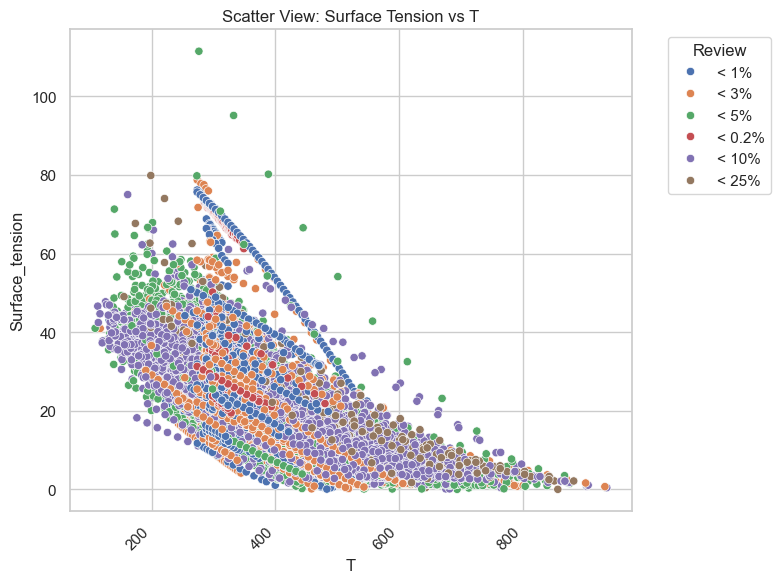

In [74]:
import matplotlib.pyplot as plt
import seaborn as sns

# Optional: nicer default styling
sns.set(style="whitegrid")

# Create figure
plt.figure(figsize=(8, 6))

# Scatter plot
sns.scatterplot(
    data=df,
    x='T',
    y='Surface_tension',
    hue='Error'
)

# Title and labels
plt.title('Scatter View: Surface Tension vs T')
plt.xlabel('T')
plt.ylabel('Surface_tension')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Legend
plt.legend(title='Review', bbox_to_anchor=(1.05, 1), loc='upper left')

# Layout adjustment
plt.tight_layout()

plt.show()

In [76]:
import plotly.express as px

fig = px.scatter(
    df,
    x='T',
    y='Surface_tension',
    #color='Family',
    hover_data=['Name', 'Family', 'Sub_Family'],
    title='Surface Tension vs T'
)

fig.update_layout(xaxis_tickangle=45)

fig.show()

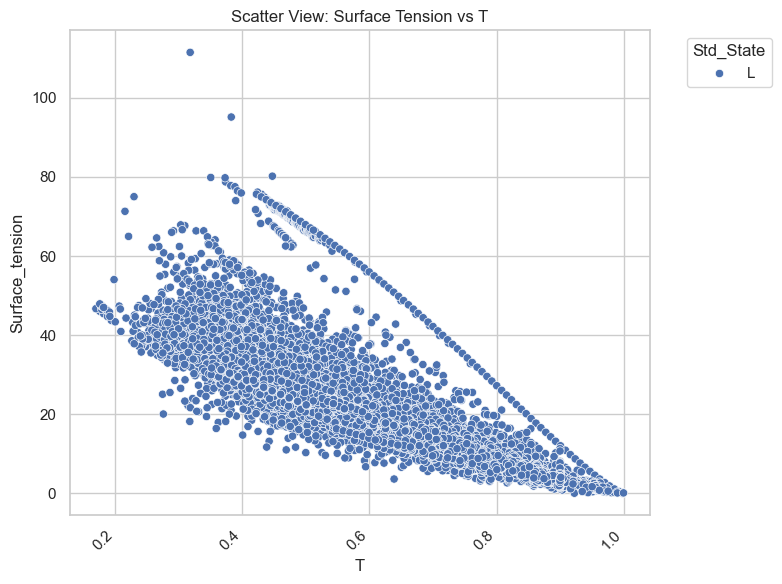

In [ ]:
# Create figure
plt.figure(figsize=(8, 6))

# Scatter plot
sns.scatterplot(
    data=df,
    x='Tr',
    y='Surface_tension',
    hue='Std_State'
)

# Title and labels
plt.title('Scatter View: Surface Tension vs T')
plt.xlabel('T')
plt.ylabel('Surface_tension')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Legend
plt.legend(title='Std_State', bbox_to_anchor=(1.05, 1), loc='upper left')

# Layout adjustment
plt.tight_layout()

plt.show()

In [ ]:
fig = px.scatter(
    df,
    x='T',
    y='Surface_tension',
    color='Std_State',
    hover_data=['Family'],
    title='Scatter View: Surface Tension vs T'
)

fig.update_layout(xaxis_tickangle=45)

fig.show()

#### ST vs T by Compound Name

In [44]:
import pandas as pd
import plotly.graph_objects as go
import plotly.express as px

# Copy dataframe
df_filt = df.copy()

df_filt["Name"] = df_filt["Name"].astype(str)
df_filt["Note"] = df_filt["Note"].fillna("No note").astype(str)

# ---------------------------------------------------------
# 1. Find Names that have AT LEAST ONE non-NA review_tag
# ---------------------------------------------------------

names_to_review = (
    df_filt.loc[df_filt["review_tag"].notna(), "Name"]
    .unique()
)

# ---------------------------------------------------------
# 2. Keep ALL rows for those Names
#    This includes both NA and non-NA review_tag rows
# ---------------------------------------------------------

df_filt = df_filt[
    df_filt["Name"].isin(names_to_review)
].copy()

# Label NA for plotting
df_filt["review_tag_plot"] = (
    df_filt["review_tag"]
    .fillna("No review")
    .astype(str)
)

names = sorted(df_filt["Name"].unique())

# ---------------------------------------------------------
# 3. Create color map
#    NA = blue
#    review tags = other colors
# ---------------------------------------------------------

review_tags = sorted(
    tag
    for tag in df_filt["review_tag_plot"].unique()
    if tag != "No review"
)

# Avoid blue because it is reserved for NA
other_colors = [
    "#EF553B",  # red
    "#00CC96",  # green
    "#AB63FA",  # purple
    "#FFA15A",  # orange
    "#19D3F3",  # cyan
    "#FF6692",  # pink
    "#B6E880",  # light green
]

color_map = {
    "No review": "blue"
}

for i, tag in enumerate(review_tags):
    color_map[tag] = other_colors[i % len(other_colors)]


# ---------------------------------------------------------
# 4. Create ONE plot per Name
# ---------------------------------------------------------

figures = {}

for name in names:

    df_name = df_filt[
        df_filt["Name"] == name
    ]

    fig = go.Figure()

    # Plot each review category
    for review_tag in df_name["review_tag_plot"].unique():

        df_sub = df_name[
            df_name["review_tag_plot"] == review_tag
        ]

        fig.add_trace(
            go.Scatter(
                x=df_sub["T"],
                y=df_sub["Surface_tension"],
                mode="markers",

                name=review_tag,

                marker=dict(
                    size=8,
                    color=color_map[review_tag]
                ),

                customdata=df_sub[["Note"]],

                hovertemplate=(
                    "T: %{x}<br>"
                    "Surface tension: %{y}<br>"
                    "Note: %{customdata[0]}<br>"
                    f"Review tag: {review_tag}"
                    "<extra></extra>"
                )
            )
        )

    fig.update_layout(
        title=f"Surface tension vs T — {name}",
        xaxis_title="T",
        yaxis_title="Surface tension",
        legend_title="Review tag",
        template="plotly_white"
    )

    figures[name] = fig

    fig.show()

In [42]:
df_filt.shape

(683, 26)

#### ST Distribution

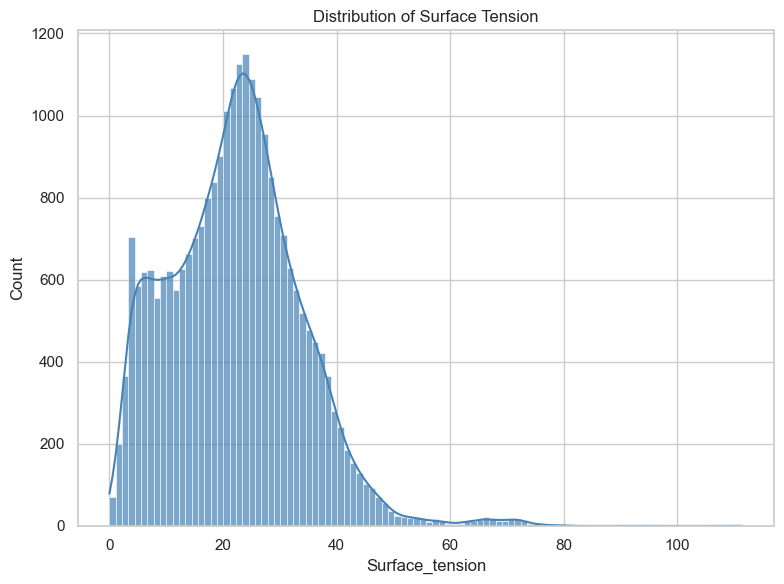

In [77]:
plt.figure(figsize=(8, 6))

sns.histplot(
    data=df,
    x="Surface_tension",
    bins=100,
    color="steelblue",
    alpha=0.7,
    kde=True
)

# Labels
plt.title("Distribution of Surface Tension")
plt.xlabel("Surface_tension")
plt.ylabel("Count")

plt.tight_layout()
plt.show()


In [78]:
import plotly.express as px
fig = px.histogram(df, x="Surface_tension", marginal="rug")
fig.show()

### Transforming SMILES into mol

Sometimes RDKit arises errors of valence when reading the SMILES when trying to generate the fingerprints. Because of that, we're going to use a try method so, if the SMILES is not correct, we're going to use the **pubchemy** library to find the SMILES using the Compound Name. 

In [79]:
df = pd.read_pickle(r'Data and variables\dippr_db_cleaned.pkl')
#Try to generate all the mol
df["mol"] = df["SMILES"].apply(Chem.MolFromSmiles)

[11:55:53] SMILES Parse Error: syntax error while parsing: C[CH2-][Al+++]1([CH2-]C)[Cl-][Al+++]([CH2-]C)([Cl-])[Cl-]1
[11:55:53] SMILES Parse Error: check for mistakes around position 13:
[11:55:53] C[CH2-][Al+++]1([CH2-]C)[Cl-][Al+++]([CH2
[11:55:53] ~~~~~~~~~~~~^
[11:55:53] SMILES Parse Error: Failed parsing SMILES 'C[CH2-][Al+++]1([CH2-]C)[Cl-][Al+++]([CH2-]C)([Cl-])[Cl-]1' for input: 'C[CH2-][Al+++]1([CH2-]C)[Cl-][Al+++]([CH2-]C)([Cl-])[Cl-]1'
[11:55:53] Explicit valence for atom # 2 O, 3, is greater than permitted
[11:55:53] Explicit valence for atom # 2 O, 3, is greater than permitted
[11:55:53] Explicit valence for atom # 2 O, 3, is greater than permitted
[11:55:53] Explicit valence for atom # 2 O, 3, is greater than permitted
[11:55:53] Explicit valence for atom # 2 O, 3, is greater than permitted
[11:55:53] Explicit valence for atom # 2 O, 3, is greater than permitted
[11:55:53] Explicit valence for atom # 2 O, 3, is greater than permitted
[11:55:53] Explicit valence for atom 

In [80]:
#Get the row index of all of those that are empty and try to look them up at pubchemy
not_valid_idx = df["mol"].isna()
not_valid_idx = not_valid_idx[not_valid_idx == True].index.to_list()

In [81]:
len(not_valid_idx)

56

In [82]:
import time
import pubchempy as pcp

# Optional but recommended: make sure flag exists
df["flag"] = None

# If mol column does not exist yet, create it
if "mol" not in df.columns:
    df["mol"] = None


def get_pubchem_results_with_retry(
    name,
    max_attempts=5,
    initial_sleep=2,
    max_sleep=60
):
    """
    Try to get PubChem compounds by name.

    If PubChem returns a 503 / ServerBusy error, wait and retry.
    If another error occurs, return the error.
    If all retries fail, return the last error.
    """

    last_error = None

    for attempt in range(max_attempts):
        try:
            results = pcp.get_compounds(name, "name")
            return results, None

        except Exception as e:
            last_error = e
            error_msg = str(e)

            is_server_busy = (
                "503" in error_msg
                or "ServerBusy" in error_msg
                or "server busy" in error_msg.lower()
                or "too many requests" in error_msg.lower()
            )

            if is_server_busy:
                sleep_time = min(initial_sleep * (2 ** attempt), max_sleep)
                print(
                    f"PubChem busy for '{name}'. "
                    f"Attempt {attempt + 1}/{max_attempts}. "
                    f"Sleeping {sleep_time} seconds..."
                )
                time.sleep(sleep_time)
                continue

            # For non-503 errors, do not retry endlessly
            return None, e

    return None, last_error


# ---------------------------------------------------------------------
# 1. Get unique names only from the rows with invalid SMILES
# ---------------------------------------------------------------------

unique_names = (
    df.loc[not_valid_idx, "Name"]
    .dropna()
    .astype(str)
    .unique()
)

pubchem_results_by_name = {}

# ---------------------------------------------------------------------
# 2. Query PubChem once per unique name
# ---------------------------------------------------------------------

for name in unique_names:
    print(f"Processing PubChem name: {name}")

    results, error = get_pubchem_results_with_retry(name)

    # Case 1: PubChem request failed even after retries
    if error is not None:
        pubchem_results_by_name[name] = {
            "SMILES": None,
            "mol": None,
            "flag": f"Not valid SMILES, PubChem request failed: {error}"
        }
        continue

    # Case 2: PubChem responded, but did not find anything
    if not results:
        pubchem_results_by_name[name] = {
            "SMILES": None,
            "mol": None,
            "flag": "Not valid SMILES, and not found in PubChem"
        }
        continue

    # Case 3: PubChem found a result
    pubchem_smiles = results[0].connectivity_smiles

    mol = Chem.MolFromSmiles(pubchem_smiles)

    if mol is None:
        pubchem_results_by_name[name] = {
            "SMILES": pubchem_smiles,
            "mol": None,
            "flag": "Not valid SMILES, PubChem SMILES also invalid"
        }
    else:
        pubchem_results_by_name[name] = {
            "SMILES": pubchem_smiles,
            "mol": mol,
            "flag": "Not valid SMILES, changed to PubChem one"
        }

    # Optional small delay even after successful requests.
    # This reduces the chance of triggering PubChem throttling.
    time.sleep(0.25)


# ---------------------------------------------------------------------
# 3. Apply results back to all matching rows in the original df
# ---------------------------------------------------------------------

for name, info in pubchem_results_by_name.items():

    # Important:
    # This updates only the rows that were originally in not_valid_idx
    # and have this specific compound name.
    mask = df.index.isin(not_valid_idx) & df["Name"].astype(str).eq(name)

    matching_idx = df.index[mask]

    for i in matching_idx:
        df.at[i, "flag"] = info["flag"]

        if info["SMILES"] is not None:
            df.at[i, "SMILES"] = info["SMILES"]

        df.at[i, "mol"] = info["mol"]


# ---------------------------------------------------------------------
# 4. Handle invalid rows where Name was missing
# ---------------------------------------------------------------------

missing_name_mask = df.index.isin(not_valid_idx) & df["Name"].isna()

df.loc[
    missing_name_mask,
    "flag"
] = "Not valid SMILES, and Name is missing so PubChem was not queried"


Processing PubChem name: ETHYL ALUMINUM SESQUICHLORIDE
Processing PubChem name: IRON PENTACARBONYL
Processing PubChem name: NICKEL CARBONYL
Processing PubChem name: cis-3-METHYL-2-HEXENE


Store the df as a pickle, so mol column remains as rdkit objects instead of strings.

In [83]:
df

,ChemID,Name,Formula,SMILES,Structure,Family,Sub_Family,Std_State,T,Surface_tension,...,Error,Error_Source,Acceptance,source_type_simplified,error_numeric,elements,has_CHOSPN,review_tag,mol,flag
0,1501,CARBON TETRACHLORIDE,CCl4,C(Cl)(Cl)(Cl)Cl,CCl4,C1/C2 ALIPHATIC CHLORIDES,C1 CHLORIDES,L,293.149994,26.75,...,< 1%,Staff,A,unknown,0.01,"{C, CL}",True,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000216A3F...,None
1,1501,CARBON TETRACHLORIDE,CCl4,C(Cl)(Cl)(Cl)Cl,CCl4,C1/C2 ALIPHATIC CHLORIDES,C1 CHLORIDES,L,298.149994,26.15,...,< 1%,Staff,A,unknown,0.01,"{C, CL}",True,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000216A3F...,None
2,1501,CARBON TETRACHLORIDE,CCl4,C(Cl)(Cl)(Cl)Cl,CCl4,C1/C2 ALIPHATIC CHLORIDES,C1 CHLORIDES,L,293.149994,26.66,...,< 1%,Author,A,experimental_raw,0.01,"{C, CL}",True,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000216A3F...,None
3,1501,CARBON TETRACHLORIDE,CCl4,C(Cl)(Cl)(Cl)Cl,CCl4,C1/C2 ALIPHATIC CHLORIDES,C1 CHLORIDES,L,288.149994,27.65,...,< 1%,Staff,A,correlated,0.01,"{C, CL}",True,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000216A3F...,None
4,1501,CARBON TETRACHLORIDE,CCl4,C(Cl)(Cl)(Cl)Cl,CCl4,C1/C2 ALIPHATIC CHLORIDES,C1 CHLORIDES,L,298.149994,26.43,...,< 1%,Staff,A,correlated,0.01,"{C, CL}",True,NaN,<rdkit.Chem.rdchem.Mol object at 0x00000216A3F...,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25644,350,SQUALENE,C30H50,CC(=CCC/C(=C/CC/C(=C/CC/C=C(/CC/C=C(/CCC=C(C)C...,CH3C(CH3)CH(CH2)2C(CH3)CH(CH2)2C(CH3)CH(CH2)2C...,ETHYL & HIGHER ALKENES,NaN,L,293.149994,31.70,...,< 3%,Staff,A,experimental_raw,0.03,{C},True,NaN,<rdkit.Chem.rdchem.Mol object at 0x000002169CD...,None
25645,21381,DIMETHYL TEREPHTHALATE,C10H10O4,c1c(C(=O)OC)ccc(C(=O)OC)c1,C6H4(COOCH3)2,AROMATIC ESTERS,NaN,L,499.850006,23.50,...,< 3%,Staff,A,experimental_raw,0.03,"{C, O}",True,2024Review,<rdkit.Chem.rdchem.Mol object at 0x000002169CD...,None
25646,21381,DIMETHYL TEREPHTHALATE,C10H10O4,c1c(C(=O)OC)ccc(C(=O)OC)c1,C6H4(COOCH3)2,AROMATIC ESTERS,NaN,L,460.950012,28.00,...,< 3%,Staff,A,experimental_raw,0.03,"{C, O}",True,2024Review,<rdkit.Chem.rdchem.Mol object at 0x000002169CD...,None
25647,21381,DIMETHYL TEREPHTHALATE,C10H10O4,c1c(C(=O)OC)ccc(C(=O)OC)c1,C6H4(COOCH3)2,AROMATIC ESTERS,NaN,L,455.350006,28.80,...,< 3%,Staff,A,experimental_raw,0.03,"{C, O}",True,2024Review,<rdkit.Chem.rdchem.Mol object at 0x000002169CD...,None


In [84]:
df = df.dropna(subset=["mol"])
df.to_pickle(r'Data and variables\dippr_db_mol_generated.pkl')

## Adding chemical descriptors

In [ ]:
df = pd.read_pickle(r'Data and variables\dippr_db_mol_generated.pkl')
df.head()

,ChemID,Name,Formula,SMILES,Structure,Family,Sub_Family,Std_State,T,Surface_tension,...,Source_Detail,Error,Error_Source,Acceptance,source_type_simplified,error_numeric,elements,has_CHOSPN,mol,flag
74,2687,BROMOTRIFLUOROMETHANE,CBrF3,FC(Br)(F)F,CBrF3,"C, H, MULTIHALOGEN COMPOUNDS",BROMO-FLUORO COMPOUNDS,V,298.149994,4.0,...,Undocumented,< 3%,Staff,A,experimental_raw,0.03,"{F, C, BR}",True,<rdkit.Chem.rdchem.Mol object at 0x000002A4281...,None
75,2688,DIBROMODIFLUOROMETHANE,CBr2F2,FC(Br)(Br)F,CBr2F2,"C, H, MULTIHALOGEN COMPOUNDS",BROMO-FLUORO COMPOUNDS,V,273.149994,20.7,...,NaN,< 5%,Staff,A,correlated,0.05,"{F, C, BR}",True,<rdkit.Chem.rdchem.Mol object at 0x000002A427E...,None
76,2688,DIBROMODIFLUOROMETHANE,CBr2F2,FC(Br)(Br)F,CBr2F2,"C, H, MULTIHALOGEN COMPOUNDS",BROMO-FLUORO COMPOUNDS,V,283.149994,19.4,...,NaN,< 5%,Staff,A,correlated,0.05,"{F, C, BR}",True,<rdkit.Chem.rdchem.Mol object at 0x000002A426D...,None
77,2688,DIBROMODIFLUOROMETHANE,CBr2F2,FC(Br)(Br)F,CBr2F2,"C, H, MULTIHALOGEN COMPOUNDS",BROMO-FLUORO COMPOUNDS,V,293.149994,17.8,...,NaN,< 5%,Staff,A,correlated,0.05,"{F, C, BR}",True,<rdkit.Chem.rdchem.Mol object at 0x000002A426D...,None
78,2688,DIBROMODIFLUOROMETHANE,CBr2F2,FC(Br)(Br)F,CBr2F2,"C, H, MULTIHALOGEN COMPOUNDS",BROMO-FLUORO COMPOUNDS,V,299.850006,17.4,...,NaN,< 5%,Staff,A,correlated,0.05,"{F, C, BR}",True,<rdkit.Chem.rdchem.Mol object at 0x000002A4281...,None


In [3]:
def mol_to_features(mol):
    row = {}

    # Polarity / electrostatics
    row["TPSA"] = Descriptors.TPSA(mol)
    row["LogP"] = Descriptors.MolLogP(mol)
    row["MaxPartialCharge"] = Descriptors.MaxPartialCharge(mol)
    row["MinPartialCharge"] = Descriptors.MinPartialCharge(mol)
    row["MaxEStateIndex"] = Descriptors.MaxEStateIndex(mol)

    # Size / dispersion
    row["MolWt"] = Descriptors.MolWt(mol)
    row["HeavyAtomCount"] = Descriptors.HeavyAtomCount(mol)

    # Hydrogen bonding
    row["NumHDonors"] = Descriptors.NumHDonors(mol)
    row["NumHAcceptors"] = Descriptors.NumHAcceptors(mol)
    row["NHOHCount"] = Descriptors.NHOHCount(mol)

    # Surface descriptors
    row["LabuteASA"] = Descriptors.LabuteASA(mol)

    for i in range(1, 13):
        row[f"SlogP_VSA{i}"] = getattr(Descriptors, f"SlogP_VSA{i}")(mol)

    for i in range(1, 15):
        row[f"PEOE_VSA{i}"] = getattr(Descriptors, f"PEOE_VSA{i}")(mol)

    for i in range(1, 11):
        row[f"SMR_VSA{i}"] = getattr(Descriptors, f"SMR_VSA{i}")(mol)

    # Structure
    row["RingCount"] = Descriptors.RingCount(mol)
    row["NumAromaticRings"] = Descriptors.NumAromaticRings(mol)
    row["NumRotatableBonds"] = Descriptors.NumRotatableBonds(mol)

    # Fingerprint
    fp = AllChem.GetMorganFingerprintAsBitVect(mol, 2, 2048)
    row["fp"] = list(fp)

    return row


chem_descriptors = df["mol"].apply(mol_to_features)

desc_df = pd.DataFrame(chem_descriptors.tolist())
desc_df.head()

[06:26:29] DEPRECATION WARNING: please use MorganGenerator
[06:26:29] DEPRECATION WARNING: please use MorganGenerator
[06:26:29] DEPRECATION WARNING: please use MorganGenerator
[06:26:29] DEPRECATION WARNING: please use MorganGenerator
[06:26:29] DEPRECATION WARNING: please use MorganGenerator
[06:26:29] DEPRECATION WARNING: please use MorganGenerator
[06:26:29] DEPRECATION WARNING: please use MorganGenerator
[06:26:29] DEPRECATION WARNING: please use MorganGenerator
[06:26:29] DEPRECATION WARNING: please use MorganGenerator
[06:26:29] DEPRECATION WARNING: please use MorganGenerator
[06:26:29] DEPRECATION WARNING: please use MorganGenerator
[06:26:29] DEPRECATION WARNING: please use MorganGenerator
[06:26:29] DEPRECATION WARNING: please use MorganGenerator
[06:26:29] DEPRECATION WARNING: please use MorganGenerator
[06:26:29] DEPRECATION WARNING: please use MorganGenerator
[06:26:29] DEPRECATION WARNING: please use MorganGenerator
[06:26:29] DEPRECATION WARNING: please use MorganGenerat

,TPSA,LogP,MaxPartialCharge,MinPartialCharge,MaxEStateIndex,MolWt,HeavyAtomCount,NumHDonors,NumHAcceptors,NHOHCount,...,SMR_VSA5,SMR_VSA6,SMR_VSA7,SMR_VSA8,SMR_VSA9,SMR_VSA10,RingCount,NumAromaticRings,NumRotatableBonds,fp
0,0.0,1.9011,0.447876,-0.160048,10.270833,148.909,5,0,0,0,...,5.085567,0.0,0.0,0.0,0.0,15.929944,0,0,0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
1,0.0,2.3265,0.355546,-0.181495,10.854167,209.815,5,0,0,0,...,3.741065,0.0,0.0,0.0,0.0,31.859888,0,0,0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
2,0.0,2.3265,0.355546,-0.181495,10.854167,209.815,5,0,0,0,...,3.741065,0.0,0.0,0.0,0.0,31.859888,0,0,0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
3,0.0,2.3265,0.355546,-0.181495,10.854167,209.815,5,0,0,0,...,3.741065,0.0,0.0,0.0,0.0,31.859888,0,0,0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
4,0.0,2.3265,0.355546,-0.181495,10.854167,209.815,5,0,0,0,...,3.741065,0.0,0.0,0.0,0.0,31.859888,0,0,0,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."


In [4]:
fp_df = pd.DataFrame(desc_df["fp"].tolist(),
                     index=desc_df.index,
                     columns=[f"fp_{i}" for i in range(2048)])

# Drop original fp column and merge
desc_df = pd.concat([desc_df.drop(columns=["fp"]), fp_df], axis=1)
desc_df.head()

,TPSA,LogP,MaxPartialCharge,MinPartialCharge,MaxEStateIndex,MolWt,HeavyAtomCount,NumHDonors,NumHAcceptors,NHOHCount,...,fp_2038,fp_2039,fp_2040,fp_2041,fp_2042,fp_2043,fp_2044,fp_2045,fp_2046,fp_2047
0,0.0,1.9011,0.447876,-0.160048,10.270833,148.909,5,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0.0,2.3265,0.355546,-0.181495,10.854167,209.815,5,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0.0,2.3265,0.355546,-0.181495,10.854167,209.815,5,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0.0,2.3265,0.355546,-0.181495,10.854167,209.815,5,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0.0,2.3265,0.355546,-0.181495,10.854167,209.815,5,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
df_new = pd.concat([df, desc_df], axis=1)
df_new.head()

,ChemID,Name,Formula,SMILES,Structure,Family,Sub_Family,Std_State,T,Surface_tension,...,fp_2038,fp_2039,fp_2040,fp_2041,fp_2042,fp_2043,fp_2044,fp_2045,fp_2046,fp_2047
74,2687.0,BROMOTRIFLUOROMETHANE,CBrF3,FC(Br)(F)F,CBrF3,"C, H, MULTIHALOGEN COMPOUNDS",BROMO-FLUORO COMPOUNDS,V,298.149994,4.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
75,2688.0,DIBROMODIFLUOROMETHANE,CBr2F2,FC(Br)(Br)F,CBr2F2,"C, H, MULTIHALOGEN COMPOUNDS",BROMO-FLUORO COMPOUNDS,V,273.149994,20.7,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
76,2688.0,DIBROMODIFLUOROMETHANE,CBr2F2,FC(Br)(Br)F,CBr2F2,"C, H, MULTIHALOGEN COMPOUNDS",BROMO-FLUORO COMPOUNDS,V,283.149994,19.4,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
77,2688.0,DIBROMODIFLUOROMETHANE,CBr2F2,FC(Br)(Br)F,CBr2F2,"C, H, MULTIHALOGEN COMPOUNDS",BROMO-FLUORO COMPOUNDS,V,293.149994,17.8,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
78,2688.0,DIBROMODIFLUOROMETHANE,CBr2F2,FC(Br)(Br)F,CBr2F2,"C, H, MULTIHALOGEN COMPOUNDS",BROMO-FLUORO COMPOUNDS,V,299.850006,17.4,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
df_new.to_pickle(r'Data and variables\df_descriptors.pkl')